# Convolutional autoencoder + latent LOF

Does local density in a learned sensor representation identify unfamiliar movement?

Read top-to-bottom: setup → equations → architecture → training → figures → LOTO → interpretation.
**Safe default:** saved-result exploration only; training is disabled.

In [1]:
from pathlib import Path
import sys
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'ml/sci_rob/vanilla/registry.py').exists()), None)
if ROOT is None:
    raise RuntimeError('Launch Jupyter within this repository.')
sys.path.insert(0, str(ROOT / 'notebooks/sci_rob/model_exploration'))
get_ipython().run_line_magic('matplotlib', 'inline')
from _exploration import *
import torch
from dataclasses import asdict
torch.set_num_threads(2)  # small architecture checks; training CLI runs separately
torch.manual_seed(0)
RUN_TRAINING = False
print('Repository:', ROOT)
print('Kernel:', sys.executable)

Repository: /Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton
Kernel: /Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton/.venv/bin/python


In [2]:
KEY = 'autoencoder'
RUN = ROOT / RUNS[KEY]
inventory(RUN)

**Artifact directory:** `ml/sci_rob/vanilla/runs/autoencoder`

,artifact,available
0,report.json,True
1,final.pt,True
2,eval_test.json,True
3,figures,True


## Data and evaluation contract

- Input: **16 channels × 200 samples**, one second at 200 Hz; stored window stride 10 samples.
- Original ID tasks: level ground (LG), ramp ascent (RA), ramp descent (RD).
  Original pseudo-OOD tasks: stair ascent (SA), stair descent (SD), standing (ST), transitions (TR).
- Participants: 12 train / 4 validation / 4 test. Task availability differs by participant.
  Input scaling is fitted on training data, never refitted on test data.
- Scoring does **not** predict a task label. High $\Psi$ means more anomalous.

$$\widetilde\Psi_t=\operatorname{median}(\Psi_{t-9},\ldots,\Psi_t),\qquad
\tau=Q_{0.995}(\widetilde\Psi_{\mathrm{train,ID}}),\qquad
\widehat o_t=\mathbf1[\widetilde\Psi_t>\tau].$$

Filtering restarts for each trial; early windows use the available history. The ten-score
filter corresponds to the repository's nominal 0.5 s smoothing setting, **not** ten raw samples.

$$\mathrm{recall}=\frac{TP}{TP+FN},\quad
\mathrm{specificity}=\frac{TN}{TN+FP},\quad J=\mathrm{recall}+\mathrm{specificity}-1.$$

AUROC measures ranking across thresholds; it is **not the fraction of OOD detected**.
OOD is the positive class. Tables below show J on −1 to 1, although source JSON stores 100J.
Scores and thresholds are not calibrated probabilities of being unsafe.

## Model and mathematics

The encoder compresses the input to 4 filters × 8 timesteps = 32 latent values:
 $$z=E_\theta(x),\qquad \widehat x=D_\theta(z),\qquad
 \mathcal L_{\rm recon}=\frac1{NCT}\sum_{n,c,t}(x_{nct}-\widehat x_{nct})^2.$$
 Encoder channels: 16 → 19 → 24 → 4, kernels 15/17/19; average pooling by 5 after the
 first two blocks. The mirrored decoder upsamples 8 → 40 → 200. Convolutions use same
 padding within an already-observed window; this is not a future forecasting model.

 **Detection uses latent LOF, not the training loss:**
 $$\Psi(x)=\operatorname{LOF}_{20}(E_\theta(x))
 =\frac1{|N_k(z)|}\sum_{u\in N_k(z)}\frac{\operatorname{lrd}_k(u)}{\operatorname{lrd}_k(z)}.$$
 Here lrd is local reachability density. The implementation uses
 `-sklearn.score_samples`, so larger means more anomalous. LOF is fitted on ID training
 latents (at most 50,000; exact duplicate latents removed).
 Reconstruction MSE is retained as a **separate diagnostic**, not silently substituted for LOF.

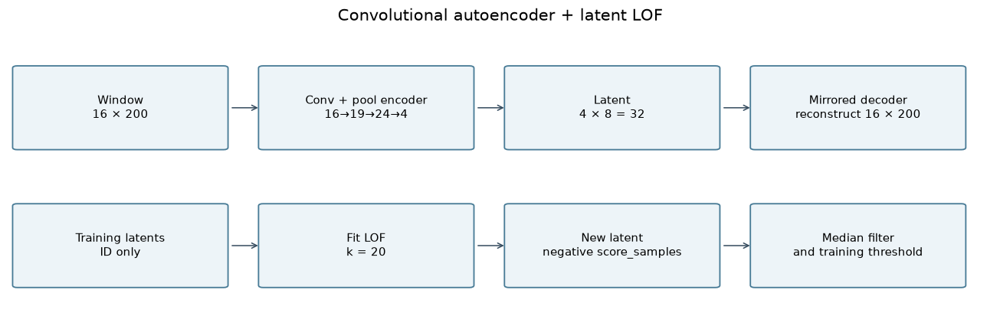

In [3]:
diagram([['Window\n16 × 200', 'Conv + pool encoder\n16→19→24→4', 'Latent\n4 × 8 = 32', 'Mirrored decoder\nreconstruct 16 × 200'], ['Training latents\nID only', 'Fit LOF\nk = 20', 'New latent\nnegative score_samples', 'Median filter\nand training threshold']], 'Convolutional autoencoder + latent LOF')

### Executable architecture check

This constructs **fresh random weights** and checks shapes only. The saved figures later come from trained runs; this dummy forward pass does not.

In [4]:
from models.autoencoder import create_autoencoder
model = create_autoencoder()
example = torch.zeros(2, 16, 200)
output = model_shapes(model, example)

ConvAutoencoder: 28,558 parameters
Input: (2, 16, 200)   Outputs: [(2, 16, 200), (2, 4, 8)]


,module,class,direct parameters
0,encoder.0,Conv1d,4579
1,encoder.1,BatchNorm1d,38
2,encoder.2,ReLU,0
3,encoder.3,AvgPool1d,0
4,encoder.4,Conv1d,7776
5,encoder.5,BatchNorm1d,48
6,encoder.6,ReLU,0
7,encoder.7,AvgPool1d,0
8,encoder.8,Conv1d,1828
9,encoder.9,BatchNorm1d,8


## Training

Single-stage reconstruction training with a participant-disjoint early-stopping split inside the training pool (configured fraction 0.2). Adam, LR 0.003, batch 1024, patience 5, maximum 200 epochs. The paper-derived LR 0.064 was a declared deviation because it collapsed this AE. The saved report shows the actual internal validation participants. LOF/threshold calibration then uses ID training data.

In [5]:
from registry import get
config_class = get(KEY).config()
display(pd.Series(asdict(config_class()), name='current default').to_frame())

,current default
lr,0.003
batch_size,1024
max_epochs,200
patience,5
val_fraction,0.2
seed,0
device,None
lof_neighbors,20
lof_fit_samples,50000
threshold_percentile,99.5


### Saved training configuration and learning curves

Current defaults can differ from a past run. Below we read the report; missing reports remain explicitly missing. Loss scales from different objectives are not directly comparable.

,saved value
lr,0.003
batch_size,1024
max_epochs,200
patience,5
val_fraction,0.2
seed,0
device,None
lof_neighbors,20
lof_fit_samples,50000
threshold_percentile,99.5


,saved result
epochs_run,42
best_epoch,36
psi_train_median,1.015187
threshold,1.242687
recon_train_median,0.260206
threshold_recon,0.892118
latent_dim,32
internal early-stopping participants,"AB18, AB28"


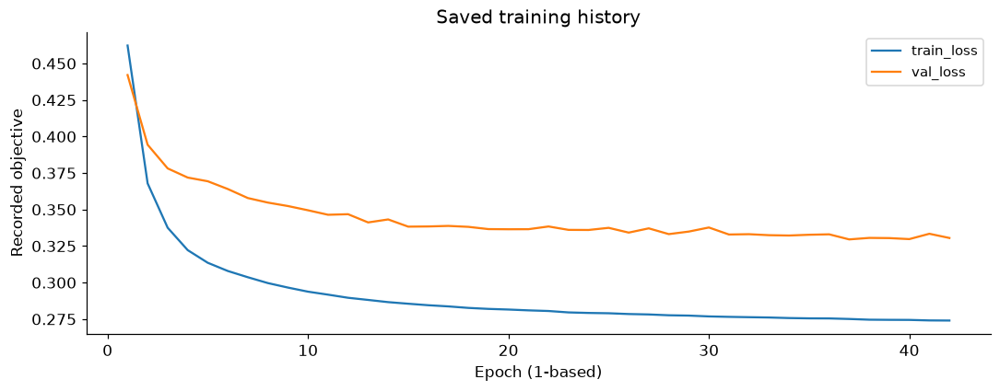

,epoch,train_loss,val_loss,seconds,best_epoch
37,37,0.274586,0.330568,4.9,36
38,38,0.274483,0.330436,4.9,36
39,39,0.274432,0.329744,4.9,36
40,40,0.274081,0.333401,4.9,36
41,41,0.274005,0.330517,5.0,36


In [6]:
config_and_history(RUN)

### Optional: run the real training pipeline

This can take hours. The commands use this kernel’s Python and write to a **new** directory. Set `RUN_TRAINING=True` in the setup cell only when ready. Existing runs are protected. After completion, set `RUN = NEW_RUN` and rerun the result cells.

In [7]:
NEW_RUN = ROOT / 'notebooks/sci_rob/model_exploration/runs' / KEY
commands = training_commands(KEY, NEW_RUN)
run_commands(commands, NEW_RUN, enabled=RUN_TRAINING)

/Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton/.venv/bin/python /Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton/ml/sci_rob/vanilla/main.py all --model autoencoder --out /Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton/notebooks/sci_rob/model_exploration/runs/autoencoder

Preview only. Set RUN_TRAINING=True explicitly to run.


## Saved test results

These values come directly from `eval_test.json`. An optimized test-ROC threshold, where reported, is diagnostic—not a validated operating point.

In [8]:
results_table(RUN)

,AUROC,recall (%),specificity (%),J (−1 to 1),threshold
score,,,,,
primary,0.7819,45.0636,93.6519,0.3872,1.2427


,mode,kind,windows,flagged_LOF_%,flagged_recon_%,median_psi,median_recon
0,LG,ID,28668,4.6498,1.0813,1.0772,0.2886
1,RA,ID,18504,6.6310,0.0000,1.1049,0.3085
2,RD,ID,14784,9.2871,0.0000,1.0730,0.2342
3,SA,OOD,10273,27.0028,0.0000,1.1362,0.2251
4,SD,OOD,10155,57.5775,0.0000,1.2843,0.2414
5,TR,OOD,1994,57.2718,0.0000,1.3055,0.1183
6,ST,OOD,621,100.0000,0.0000,1.4153,0.0741


## Model behavior through figures

Images are embedded from the existing run, without rewriting it. Captions explain what each figure can and cannot establish.

**ae_latent_space.png** — PCA view of saved latents. This existing figure fits PCA to ID evaluation latents for visualization only; it is not the LOF fitting procedure.

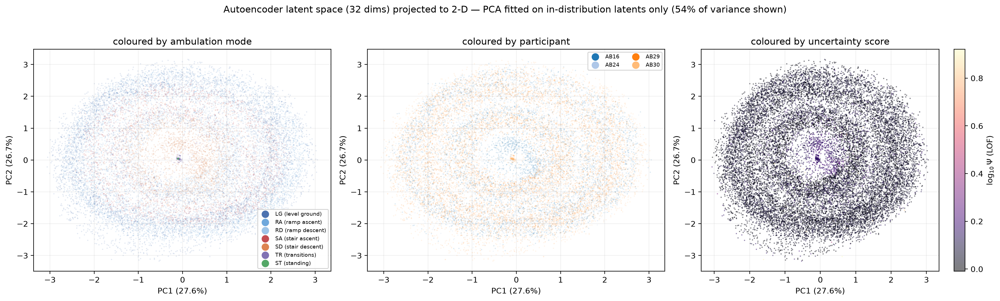

**ae_latent_dims.png** — Latent variation: look for inactive/collapsed dimensions.

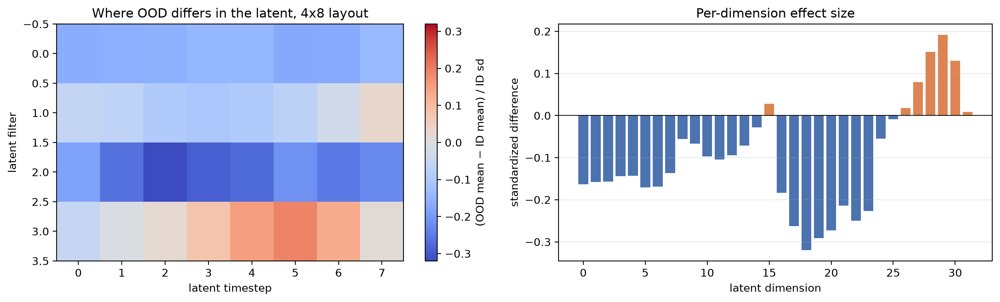

**ae_reconstructions.png** — Input versus reconstruction; easy reconstruction is not proof of familiarity.

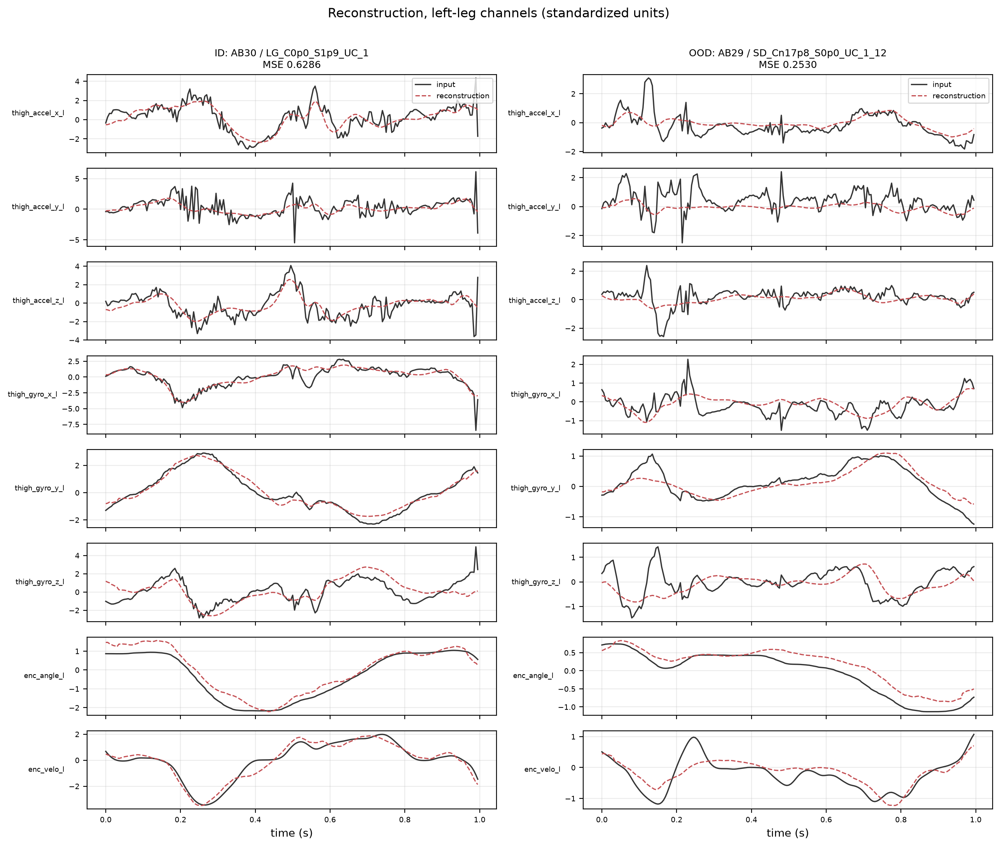

**ae_score_comparison.png** — LOF versus reconstruction error: different scores can rank the same tasks differently.

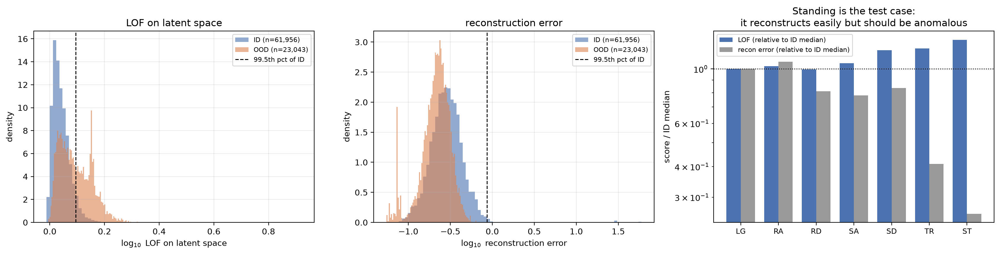

**ae_psi_by_task.png** — Latent-density scores, per-task spread and threshold.

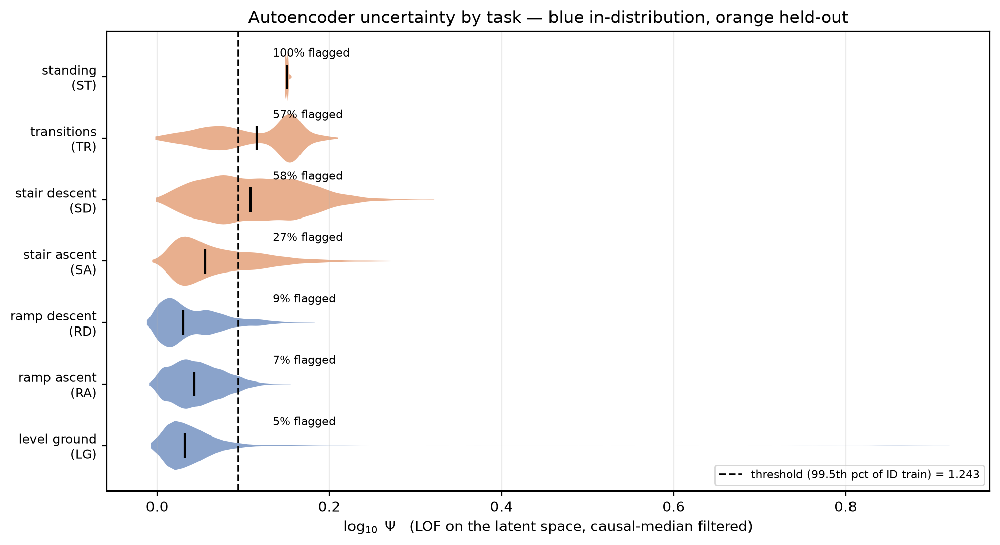

**ae_detection_by_task.png** — Per-task flags at the saved threshold.

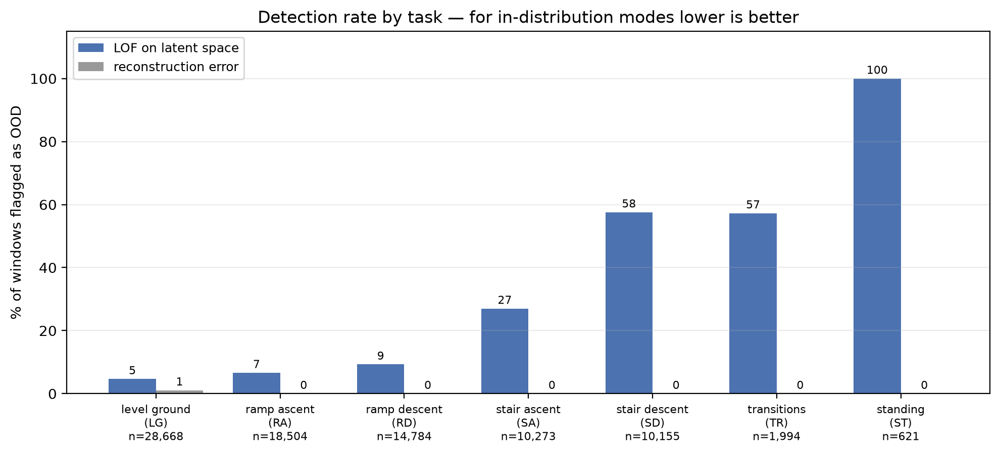

In [9]:
gallery(RUN, [('ae_latent_space.png', 'PCA view of saved latents. This existing figure fits PCA to ID evaluation latents for visualization only; it is not the LOF fitting procedure.'), ('ae_latent_dims.png', 'Latent variation: look for inactive/collapsed dimensions.'), ('ae_reconstructions.png', 'Input versus reconstruction; easy reconstruction is not proof of familiarity.'), ('ae_score_comparison.png', 'LOF versus reconstruction error: different scores can rank the same tasks differently.'), ('ae_psi_by_task.png', 'Latent-density scores, per-task spread and threshold.'), ('ae_detection_by_task.png', 'Per-task flags at the saved threshold.')])

## Interactive views of the saved latent space: UMAP, PCA and raw latent coordinates

Same 32-D test latents as `ae_latent_space.png`, now interactive and task-coloured. UMAP and PCA are **fitted on in-distribution latents only** (a random subset) and every task is then transformed into that fixed map, mirroring the discipline of the saved PCA figure; the latent panel is the untransformed coordinates. The hover text carries the saved smoothed LOF score.

**Three projections of the same rows.** `umap` is nonlinear and neighbourhood-preserving:
distances, cluster areas and gaps are not measurements. `pca` is linear, fitted on the same
reference rows, and its axis labels carry the explained variance. `latent` is two or three raw
latent coordinates with no transformation at all: the only view in which a distance is a true
latent distance, at the price of showing 2-3 of 32 dimensions (`LATENT_DIMS = None` picks the
highest-variance ones on the reference rows; give a tuple such as `(0, 8, 16)` to choose).

**Layout.** In 2-D and in 3-D the projections are side-by-side panels of one figure (the VAE's
view buttons switch all panels together). Every 3-D panel is a WebGL scene, browsers allow only
about 8-16 live WebGL contexts per page, and JupyterLab is one page for every open notebook: a
three-panel 3-D figure costs three. If a 3-D panel ever shows its legend but a blank scene, close
the other notebook tabs and reload the page. 2-D maps are SVG and never hit that cap.

**How to move around (Plotly):** scroll to zoom, drag to pan (2-D) or rotate (3-D; right-drag
pans), double-click to reset. Click a task in the legend to hide it in every panel; double-click
a task to isolate it. Hover shows the participant and trial. `VIEW_DIMS` selects `(2,)`, `(3,)`
or `(2, 3)`; `PROJECTIONS` selects which projections appear. With `SAVE_HTML = True` each figure
is also written as a standalone page under `notebooks/sci_rob/model_exploration/interactive/` (ignored
by git) for full-screen browsing.

Every task keeps **one fixed colour and marker symbol**, whatever role a protocol assigns it.
UMAP embeddings are cached under `.cache/`; delete that folder to recompute.

In [10]:
from _umap_exploration import ae_latent_views, task_counts
VIEW_DIMS = (2, 3)                       # (2,), (3,) or (2, 3)
PROJECTIONS = ('umap', 'pca', 'latent')  # side-by-side panels in 2-D and 3-D
LATENT_DIMS = None                       # e.g. (0, 8, 16); None = highest-variance latent coordinates
MAX_POINTS = 12_000                      # stratified sample; standing and transitions keep every window
VIEW_SEED = 0
SAVE_HTML = True                         # standalone copies under notebooks/sci_rob/model_exploration/interactive/
ae_views = ae_latent_views(RUN, dims=VIEW_DIMS, projections=PROJECTIONS, latent_dims=LATENT_DIMS,
                           max_points=MAX_POINTS, seed=VIEW_SEED, save_html=SAVE_HTML)

Standalone interactive copy: notebooks/sci_rob/model_exploration/interactive/ae_autoencoder_views_2d.html


Standalone interactive copy: notebooks/sci_rob/model_exploration/interactive/ae_autoencoder_views_3d.html


## Leave-one-task-out (LOTO) stress test

SA: stair ascent; ST: standing; TR: transitions. Each run excludes the named task from **all training participants**, trains on the other six, and tests on held-out participants. This differs from LOSO epoch selection.

Standing test data come from one trial of one participant: 621 overlapping windows, or 600 for the gait-phase subset. Gait-phase LOTO uses fewer labelled windows overall. Raw window counts are not independent repetitions; cross-run changes do not isolate a causal training effect.

,held out,score,AUROC,recall (%),ID false alarms (%),J,OOD windows
0,SA,primary,0.7124,0.4088,2.0930,-0.0168,10273
1,ST,primary,0.9908,100.0000,1.7422,0.9826,621
2,TR,primary,0.8759,45.0351,1.5312,0.4350,1994


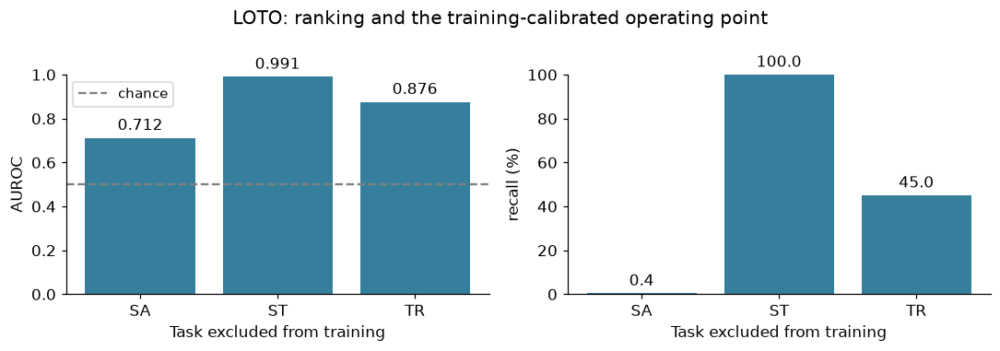

In [11]:
loto_results(KEY)

## LOTO score spread and threshold what-if

Each figure uses one separately trained holdout run: **only the named held-out task is
orange (OOD)**; the other six are blue (ID). The black dashed line is that run's saved
training threshold. Black bars span the middle 50% (IQR), with a tick at the median.
Density shapes use at most 1,500 quantile-spaced points per task; all medians, IQRs and
flag rates use **every saved test window**. Non-GAN scores use log10 axes when positive.
The plotted scores already include the original per-trial smoothing; they are not filtered again.

$$\operatorname{recall}(\tau)=\frac{\sum_{i:y_i=1}\mathbf{1}[\widetilde\Psi_i>\tau]}{N_{\rm OOD}},
\qquad \operatorname{FPR}(\tau)=\frac{\sum_{i:y_i=0}\mathbf{1}[\widetilde\Psi_i>\tau]}{N_{\rm ID}}.$$

**Try a threshold:** replace a `None` in `LOTO_THRESHOLDS` with a numeric score threshold
(in original units, **not log10**), then rerun this cell. A purple line and exact per-task
flag rates show the what-if; `None` uses the saved threshold. The right-hand staircase
and table show recall **and ID false alarms**, not AUROC. Changing the threshold does
not change AUROC, retrain anything, or overwrite saved results.

These are **exploratory test-set what-ifs**, not validated new operating points. Choose a
final threshold using validation data, not whichever test threshold looks best. Rates
are window-weighted; overlapping windows (especially the single standing trial) are
not independent repetitions. Missing runs remain explicitly unavailable.

### Held out: SA — stair ascent

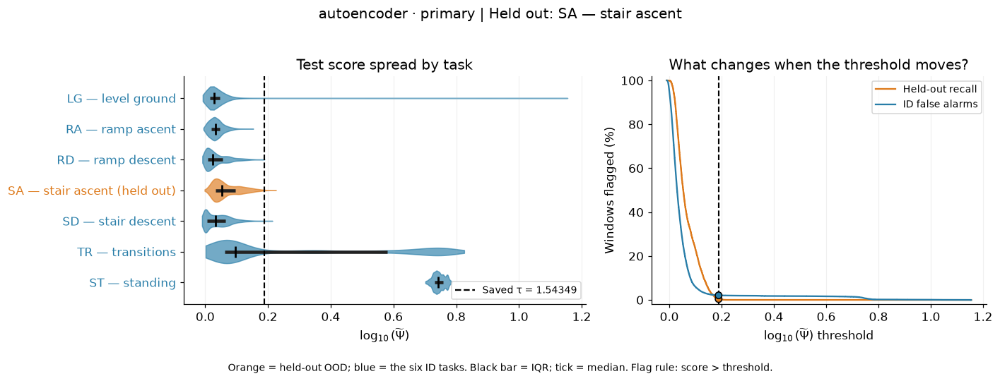

,point,threshold,OOD recall (%),ID false alarms (%)
0,,0.77174494,100.00,100.00
1,,1.1576174,40.54,17.83
2,,1.3891409,6.79,2.87
3,,1.4663154,2.32,2.35
4,,1.528055,0.65,2.10
5,saved,1.5434899,0.41,2.09
6,,1.5589248,0.37,2.08
7,,1.6206644,0.07,2.04
8,,1.6978389,0.00,2.01
9,,1.9293623,0.00,1.95


**Per-task flags at τ = 1.5434899** (recall on the held-out task; false alarms on each ID task).

,task,role,windows,flagged (%)
0,LG,ID,28668,0.61
1,RA,ID,18504,0.00
2,RD,ID,14784,0.02
3,SA,held-out OOD,10273,0.41
4,SD,ID,10155,0.14
5,TR,ID,1994,37.71
6,ST,ID,621,100.00


### Held out: ST — standing

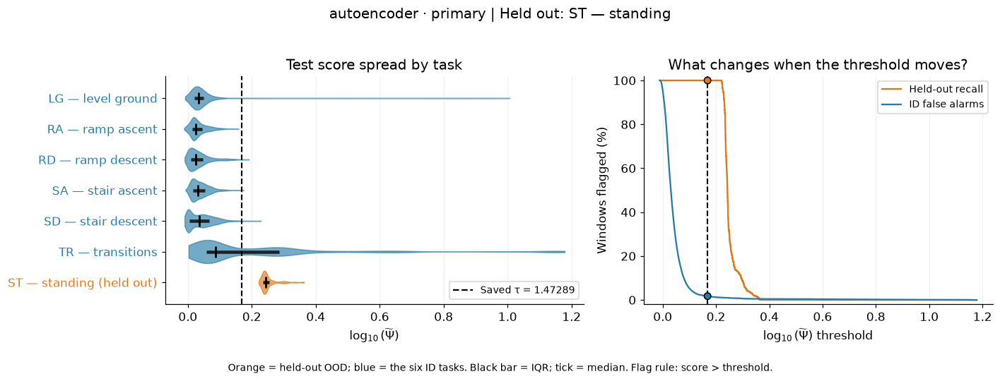

,point,threshold,OOD recall (%),ID false alarms (%)
0,,0.73644745,100.00,100.00
1,,1.1046712,100.00,33.39
2,,1.3256054,100.00,3.10
3,,1.3992502,100.00,2.18
4,,1.4581659,100.00,1.80
5,saved,1.4728949,100.00,1.74
6,,1.4876238,100.00,1.69
7,,1.5465396,100.00,1.39
8,,1.6201844,100.00,1.17
9,,1.8411186,17.39,0.84


**Per-task flags at τ = 1.4728949** (recall on the held-out task; false alarms on each ID task).

,task,role,windows,flagged (%)
0,LG,ID,28668,1.98
1,RA,ID,18504,0.00
2,RD,ID,14784,0.16
3,SA,ID,10273,0.01
4,SD,ID,10155,0.51
5,TR,ID,1994,41.32
6,ST,held-out OOD,621,100.00


### Held out: TR — transitions

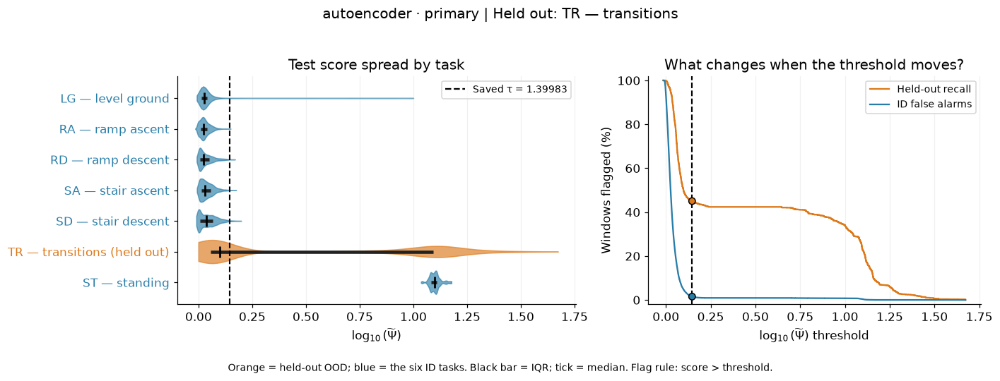

,point,threshold,OOD recall (%),ID false alarms (%)
0,,0.69991306,100.00,100.00
1,,1.0498696,96.59,58.44
2,,1.2598435,49.15,4.53
3,,1.3298348,46.19,2.47
4,,1.3858279,45.19,1.64
5,saved,1.3998261,45.04,1.53
6,,1.4138244,44.93,1.42
7,,1.4698174,44.18,1.18
8,,1.5398087,43.63,1.02
9,,1.7497827,42.38,0.91


**Per-task flags at τ = 1.3998261** (recall on the held-out task; false alarms on each ID task).

,task,role,windows,flagged (%)
0,LG,ID,28668,1.54
1,RA,ID,18504,0.03
2,RD,ID,14784,0.31
3,SA,ID,10273,0.29
4,SD,ID,10155,1.24
5,TR,held-out OOD,1994,45.04
6,ST,ID,621,100.00


In [12]:
from _loto_exploration import loto_score_explorer, threshold_rates
LOTO_THRESHOLDS = {'SA': None, 'ST': None, 'TR': None}
LOTO_SCORE = 'primary'
loto_bundles = loto_score_explorer(KEY, score=LOTO_SCORE, thresholds=LOTO_THRESHOLDS)
# Exact custom query, e.g.: threshold_rates(loto_bundles['ST'], [0.59, 0.60])

## Takeaway and next checks

AE + LOF has the strongest worst-holdout AUROC among the primary scores in the completed LOTO matrix, but its stair-ascent recall at the saved threshold is very low. Ranking robustness is not deployment readiness.

Keep score/threshold selection on validation data. Report both ranking and recall at a declared false-alarm budget, repeat seeds, and quantify participant/trial-level variation before making robustness claims.

In [13]:
source_links(['ml/common/models/autoencoder.py', 'ml/sci_rob/vanilla/training/autoencoder.py', 'ml/sci_rob/vanilla/evaluation/autoencoder.py'])

Implementation sources: [autoencoder.py](../../../ml/common/models/autoencoder.py), [autoencoder.py](../../../ml/sci_rob/vanilla/training/autoencoder.py), [autoencoder.py](../../../ml/sci_rob/vanilla/evaluation/autoencoder.py)